# **Aprendizado Não Supervisionado** (*Unsupervised Learning*)

## 3. Algoritmos de Agrupamento (*Clustering*)

Vimos como a utilizar o modelo **PCA** para enxergar dados complexos de alta dimensão em um plano bidimensional. Agora vamos explorar a segunda grande vertente do **Aprendizado Não Supervisionado**: o **Agrupamento** (*Clustering*).

Enquanto a redução de dimensionalidade atua nas *colunas* (atributos), o agrupamento atua nas *linhas* (amostras), unindo instâncias similares em grupos coesos chamados *clusters*. Vamos estudar o algoritmo mais popular dessa categoria, o **K-Means**, o qual agrupa os dados em `K` grupos distintos.  

### 3.1 K-Means
O **K-Means** (*K-Médias*) é  o algoritmo de agrupamento mais popular da ciência de dados devido à sua simplicidade matemática, facilidade de implementação e excelente desempenho em diferentes tarefas. Ele pertence à classe dos **Algoritmos de Particionamento** que dividem simultaneamente os pontos de dados em grupos distintos chamados **Clusters** (agrupamentos).  
*(Nota: Uma abordagem alternativa são os algoritmos de **agrupamento hierárquico**, que partem de grupos iniciais e os dividem ou fundem sucessivamente)*.

#### 3.1.1 Princípio Matemático e Limitação A Priori
A ideia central do **K-Means** consiste em encontrar uma partição dos pontos de dados de tal forma que a soma das distâncias ao quadrado entre o centro médio do *cluster* (**centroide**) e cada ponto pertencente àquele *cluster* seja mínima (grandeza conhecida como *inércia*). O método **K-Means** exige que a quantidade de *clusters*, `K`, seja conhecida *a priori* (de antemão)!

#### 3.1.2 Funcionamento 
O algoritmo opera de forma iterativa através dos seguintes passos:

1. Definição de K: O usuário escolhe a quantidade de *clusters* (grupos) que deseja formar.
2. Inicialização dos centroides: São escolhidos `K` pontos iniciais no espaço de dados para representar os centros dos grupos.
3. Atribuição de pontos: Cada dado do conjunto é associado ao centróide mais próximo, geralmente utilizando como medida a distância euclidiana.
4. Atualização dos centroides: A posição de cada centróide é recalculada, tornando-se a média aritmética de todos os pontos atribuídos àquele grupo.
5. Convergência: Os passos 3 e 4 se repetem até que os centroides não se movam mais de forma significativa ou atinjam o limite de iterações.

#### 3.1.3 Algoritmo
No problema de Agrupamento, nos é dado um conjunto de treinamento ${x_{1}, ... , x_{n}}$, e querem agrupar os dados em alguns "*clusters*". Aqui, os dados são representados por vetores de características (atributos) para cada ponto de dados $x_{i} \in \mathbb{R}^n$; mas sem rótulos $y_i$, tornando isso um problema de aprendizagem não supervisionada. Nosso objetivo é prever $K$ centroides e um rótulo $c_i$ para cada ponto de dados. Segue algoritmo de agrupamento K-Means:  

- (b) Selecione K pontos como centroides iniciais: $\mu_1, \mu_2, ..., \mu_N \in \mathbb{R}^n$
- Repita até que os centroides não mudem
    - Repita
        - (c), (e) Forma K grupos associando todos os pontos aos centroides mais próximos: $c_i = \rm{arg~} \displaystyle \min_{j} \lVert x_i - \mu_j \rVert ^2 $
        - (d), (f) Calcule o centróide (ponto médio dos pontos associados) de cada grupo: $\mu_j = \frac{\sum _{i=1}^N l\{c_i = j\}x_i}{\sum _{i=1}^N \{c_i = j\}}$

<img src="./img/alg_k_means.png" width="700px">  

**Figura 1** - Separação dos pontos em dois grupos (*clusters*). Exemplos de treinamento são mostrados como pontos, e os centroides dos *clusters* são mostrados com a marca **x**. (a) Conjunto de dados original. (b) Centroides de *cluster* inicial aleatório. (c-f) Ilustração de execução de duas iterações do **K-Means**. Em cada iteração, atribuímos em cada exemplo de treinamento, ao centroide do *cluster* mais próximo (mostrado os exemplos de treinamento da mesma cor que o centroide do *cluster* para o qual é atribuído); em seguida, movemos cada centroide para a média dos pontos que lhe são atribuídos.

O algoritmo **K-Means** é sensível à posição inicial das sementes (seleção dos centroides iniciais). É importante rodar o algoritmo diversas vezes para se obter resultados mais significativos.  

<img src="./img/sens_início.png" width="auto"> 

**Figura 2** - Sensibilidade do algoritmo à escolha dos centroides iniciais.

#### 3.1.4 Escolha da Quantidade de *Clusters* (`K`)
* Método *Elbow* (cotovelo): Usa a distância quadrática média dos pontos do *cluster* até o seu centróide (*Within-Cluster Sum of Squares* - WCSS), para diferentes valores de `K`.
$$WCSS = \sum _{k=1} ^{N_C} \sum _{\bold{x} \in C_k} dist(\bold{x},\bar{x}_{C_k})^2$$

O objetivo é identificar o ponto em que a taxa de redução do WCSS sofre uma mudança brusca, indicando que a adição de mais *clusters* (além desse ponto) resulta em retornos decrescentes. O ponto de "cotovelo" sugere o número ideal de *clusters*, `K` ideal, a partir do qual a melhoria passa a ser mais lenta.

<img src="./img/elbow_method.webp" width="500px">  

#### 3.1.5 Métricas do Método do Cotovelo: Distorção e Inércia
Duas métricas comumente usadas no **Método do Cotovelo** são a **Distorção** e a **Inércia**.

A. **Distorção**: mede a distância quadrática média entre cada ponto de dados e o centro do *cluster* atribuído. É uma medida de quão bem os *clusters* representam os dados. Um valor de distorção menor indica um agrupamento melhor.

$$\text{Distorcao} ​=\frac{1}{n}\sum_{i=1}^{n}\min_{c \in \text{clusters}} \left\| x_i - c \right\|^2 $$

onde,
* $x_i$ é i-ésimo ponto de dados
* $c$ é o centróide do *cluster* do conjunto de todos os centroides dos clusters
* $\left \| x_i − c \right \|^2$ é a distância euclidiana ao quadrado entre o ponto de dados e o centróide do *cluster*
* $n$ é o número total de pontos de dados

B. **Inércia**: é a soma dos quadrados das distâncias de cada ponto de dados ao centróide do *cluster* mais próximo. É essencialmente o erro quadrático total do agrupamento. Assim como a **distorção**, um valor de **inércia** menor sugere um agrupamento melhor.

$$\text{Inércia} = \sum_{i=1}^{n} \text{dist}(x_i, c_j^*)^2$$

No Método do Cotovelo, calculamos a **distorção** ou a **inércia** para diferentes valores de `k` e as representamos graficamente. O ponto em que a diminuição começa a desacelerar, ponto do "cotovelo", geralmente indica o número ideal de *clusters*.

#### 3.1.6 Implementação do **Método do Cotovelo**

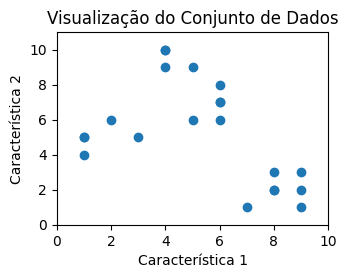

In [36]:
from sklearn.cluster import KMeans
from sklearn import metrics
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt

# Criação dos dados
x1 = np.array([3, 1, 1, 2, 1, 6, 6, 6, 5, 6, 7, 8, 9, 8, 9, 9, 8, 4, 4, 5, 4])
x2 = np.array([5, 4, 5, 6, 5, 8, 6, 7, 6, 7, 1, 2, 1, 2, 3, 2, 3, 9, 10, 9, 10])
X = np.array(list(zip(x1, x2))).reshape(len(x1), 2)

# Visualização dos dados
plt.figure(figsize=(3.5,2.5))
plt.scatter(x1, x2, marker='o')
plt.xlim([0, 10]); plt.ylim([0, 11])
plt.title('Visualização do Conjunto de Dados')
plt.xlabel('Característica 1'); plt.ylabel('Característica 2')
plt.show()

A partir da visualização dos dados (célula anterior), vemos que o número ideal de *clusters* deve ser em torno de 3. Mas visualizar os dados por si só nem sempre fornece a resposta correta. Portanto, vamos medir a **distorção** e a **inércia** do método cotovelo...

Distorção: 1: 14.902, 2:  5.146, 3:  1.882, 4:  0.856, 5:  0.717, 6:  0.548, 7:  0.433, 8:  0.382, 9:  0.334, 
Inércia:   1:312.952, 2:108.071, 3: 39.517, 4: 17.979, 5: 15.050, 6: 11.517, 7:  9.083, 8:  8.017, 9:  7.017, 

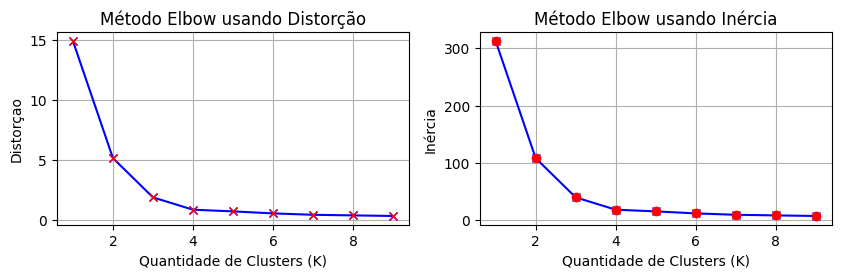

In [39]:
# Vamos ajustar o modelo K-means para diferentes valores de k (qtde de clusters) e calcular a distorção e a inércia para cada valor
distorcao, inercia = [], []
mapeamento1, mapeamento2 = {}, {}
K = range(1, 10)
for k in K:
    modeloKMeans = KMeans(n_clusters=k, random_state=42).fit(X)
    distorcao.append(sum(np.min(cdist(X, modeloKMeans.cluster_centers_, 'euclidean'), axis=1)**2) / X.shape[0])
    inercia.append(modeloKMeans.inertia_)
    mapeamento1[k] = distorcao[-1]
    mapeamento2[k] = inercia[-1]

# Mostra distorção e inércia
print("Distorção: ", end='')
for key, val in mapeamento1.items():
    print(f'{key}:{val:7.3f}, ', end='')
print("\nInércia:   ", end='')
for key, val in mapeamento2.items():
    print(f'{key}:{val:7.3f}, ', end='')

plt.figure(figsize=(10,2.5))
plt.subplot(1,2,1)
plt.plot(K, distorcao, 'bx-'); plt.plot(K, distorcao, 'rx')
plt.xlabel('Quantidade de Clusters (K)'); plt.ylabel('Distorçao')
plt.title('Método Elbow usando Distorção'); plt.grid(True)
plt.subplot(1,2,2)
plt.plot(K, inercia, 'bx-'); plt.plot(K, inercia, 'ro')
plt.xlabel('Quantidade de Clusters (K)'); plt.ylabel('Inércia')
plt.title('Método Elbow usando Inércia'); plt.grid(True)
plt.show()

Pontos de dados agrupados para diferentes valores de `k`:   
Vamos criar gráficos com os pontos de dados agrupados para diferentes valores de `k`. Para isso, aplicaremos o algoritmo **K-Means** ao conjunto de dados, iterando sobre uma variedade de valores de `k`.

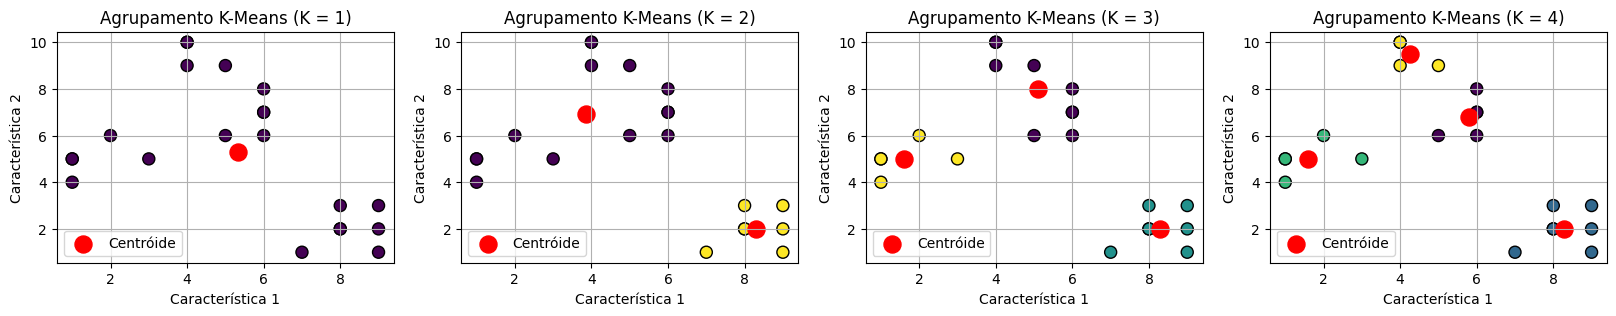

In [45]:
# Agrupamento para diferentes valores de `k`
plt.figure(figsize=(20,3))
# plt.subplots(1,4)
for k in range(1, 5):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    y_kmeans = kmeans.fit_predict(X)
    plt.subplot(1,4,k)
    plt.scatter(X[:,0], X[:,1], c=y_kmeans, cmap='viridis', marker='o', edgecolor='k', s=75)
    plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], s=150, c='red', label='Centróide', marker='o', edgecolor='r')
    plt.title(f'Agrupamento K-Means (K = {k})')
    plt.xlabel('Característica 1'); plt.ylabel('Característica 2')
    plt.legend(loc='lower left'); plt.grid();
plt.show()

#### Exercício

1. O que o Método do Cotovelo (*Elbow Method*) ajuda a determinar no Modelo de Agrupamento K-Means? 

A. Número ideal de *clusters*.  
B. Centroides dos *clusters*.  
C. Escalonamento de atributos/características (*features*).  
D. Valores atípicos (*outliers*).  

#### 3.1.7 Aplicação Prática
Vamos demonstrar o funcionamento do algoritmo **K-Means** com os dígitos manuscritos (`load_digits`). Depois de carregar os dados, aplicamos a função `scale()` do módulo `sklearn.preprocessing` para padronizar a escala numérica dos *pixels* (média zero e variância unitária), evitando que variações extremas de brilho distorçam o cálculo das distâncias ao centroides:

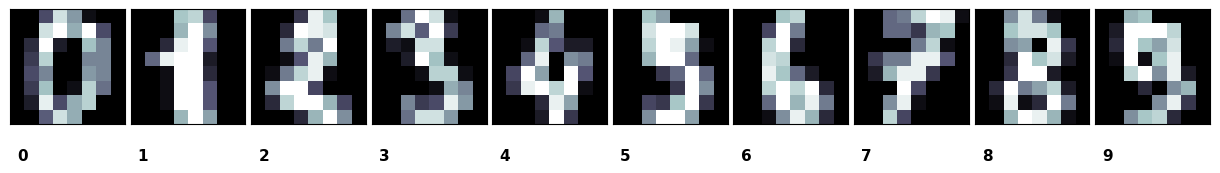

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import scale

# Carrega a base de dígitos manuscritos e padroniza a escala dos 64 pixels (média 0, variância 1)
digitos = load_digits()
dados = scale(digitos.data)

# Exibe até 10 dígitos lado a lado com nitidez
def print_digits(imagens, y, max_n=10):
    # fig = plt.figure(figsize=(10, 12))
    fig = plt.figure(figsize=(12, 12))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)
    i = 0
    while i < max_n and i < imagens.shape[0]:
        p = fig.add_subplot(1, 10, i + 1, xticks=[], yticks=[])
        p.imshow(imagens[i], cmap=plt.cm.bone)
        # rotula a imagem com o valor alvo
        p.text(0, 10, str(y[i]), fontsize=11, fontweight='bold')
        i = i + 1
    plt.show()
    
print_digits(digitos.images, digitos.target, max_n=10)

Você pode notar na figura acima que o conjunto de dados traz o número correspondente associado como classe alvo (`0` a `9`). Contudo, como estamos realizando **Agrupamento Não Supervisionado**, **não utilizaremos essa informação durante o treinamento** — ela servirá apenas no final para avaliarmos a qualidade dos grupos formados! O nosso objetivo é verificar se o computador consegue reunir sozinho as imagens em 10 grupos baseando-se unicamente na semelhança geométrica dos pixels.

##### Separação de Dados para Treinamento e Teste

In [63]:
# Atualizado do Python 2 (sklearn.cross_validation -> sklearn.model_selection)
from sklearn.model_selection import train_test_split

# Dividindo os dados padronizados, os rótulos e as imagens em Treino (75%) e Teste (25%)
X_treino, X_teste, y_treino, y_teste, imagens_treino, imagens_teste = train_test_split(dados, digitos.target, digitos.images, test_size=0.25, random_state=42)

n_amostras, n_atributos = X_treino.shape
n_digitos = len(np.unique(y_treino))
rotulos = y_treino

##### Etapas do Algoritmo K-Means
A partir do instante que temos o conjunto de dados para o treinamento (75%), estamos prontos para instanciar os agrupamentos, aplicando o algoritmo **K-Means**, que opera iterativamente em **três passos**:
1. **Inicialização**: Seleciona aleatoriamente um conjunto inicial de `K` pontos no espaço para atuarem como os centros dos grupos (**centroides**).

2. **Atribuição**: Calcula a distância de cada amostra até os centroides e atribui cada ponto ao grupo cujo centroide estiver mais próximo.

3. **Atualização**: Recalcula a posição dos centroides tirando a média aritmética das coordenadas de todos os pontos que caíram naquele grupo.  
Os passos 2 e 3 são repetidos até que os grupos se estabilizem, ou seja, até que pouquíssimos pontos mudem de grupo a cada nova iteração.

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">⚠️ <b>O Problema dos Mínimos Locais e o Parâmetro <code>k-means++</code>:</b></p>
    Dependendo de onde os centroides iniciais forem sorteados, o <b>K-Means</b> pode convergir para uma solução ruim (<i>mínimo local</i>). <br> 
    Para mitigar isso, o <code>scikit-learn</code> oferece dois recursos automáticos:<br>
    &bull; <b><code>n_init=10</code>:</b> Executa o algoritmo 10 vezes com sorteios iniciais diferentes e escolhe automaticamente a configuração que obteve a menor inércia (menor soma das distâncias ao quadrado).<br>
    &bull; <b><code>init='k-means++'</code>:</b> Posiciona os centroides iniciais bem afastados uns dos outros antes de começar, acelerando a convergência e melhorando os resultados.
</div>

Primeiras 10 imagens de treino e o número do Cluster atribuído pelo K-Means:


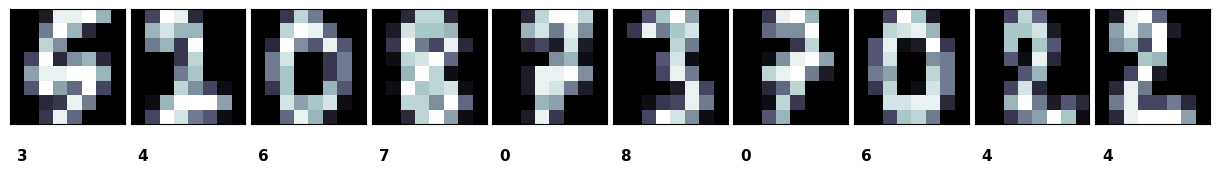

In [68]:
from sklearn import cluster

# Instancia e treina o K-Means. Obs.: Passamos APENAS 'X_treino' ao método .fit()
clf = cluster.KMeans(init='k-means++', n_clusters=10, n_init=10, random_state=42)
clf.fit(X_treino)

# Exibindo as 10 primeiras imagens de treino e o número do cluster atribuído a cada uma (clf.labels_)
print("Primeiras 10 imagens de treino e o número do Cluster atribuído pelo K-Means:")
print_digits(imagens_treino, clf.labels_, max_n=10)

##### Predição e Inspeção Visual dos Agrupamentos Formados

Observe os números abaixo (rótulos) das imagens na célula anterior: **o número de identificação do cluster (`0` a `9`) não tem relação direta com o valor real do algarismo manuscrito**! Como o algoritmo nunca viu os rótulos verdadeiros, o "Cluster 6", por exemplo, é apenas uma etiqueta arbitrária (como "Grupo G") onde o computador reuniu imagens parecidas.

Para prever em qual *cluster* cada amostra do **Conjunto de Teste (`X_teste`)** se encaixa, utilizamos o método habitual `.predict()` e inspecionamos até 10 imagens de cada um dos 10 grupos criados:

--- Amostras reunidas no Cluster de índice 0 ---


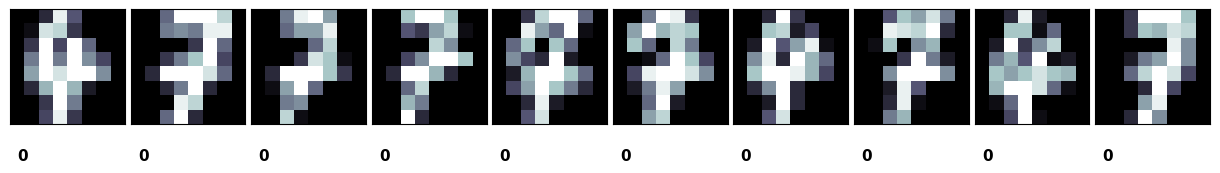

--- Amostras reunidas no Cluster de índice 1 ---


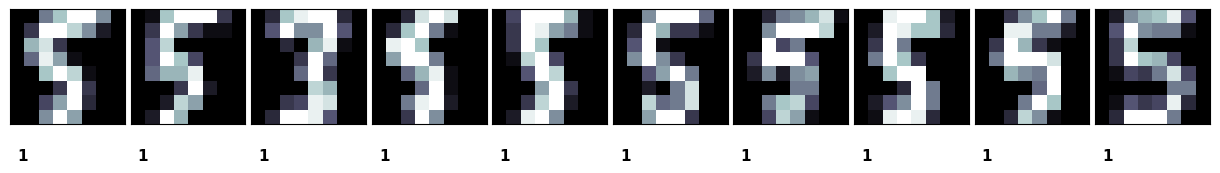

--- Amostras reunidas no Cluster de índice 2 ---


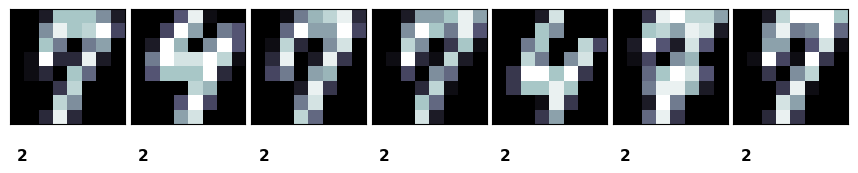

--- Amostras reunidas no Cluster de índice 3 ---


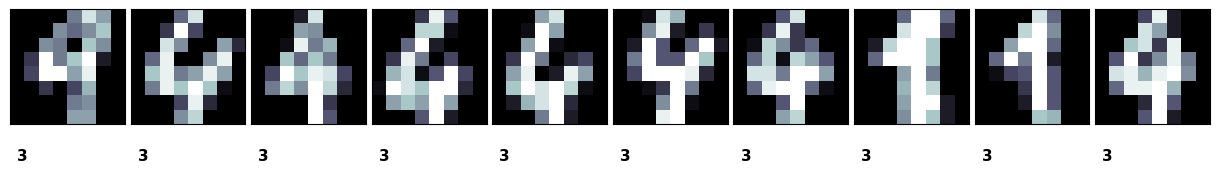

--- Amostras reunidas no Cluster de índice 4 ---


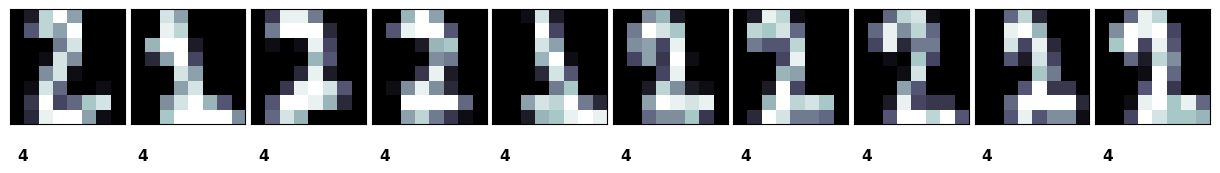

--- Amostras reunidas no Cluster de índice 5 ---


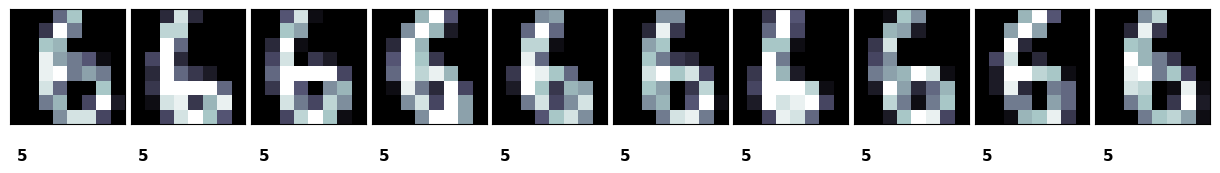

--- Amostras reunidas no Cluster de índice 6 ---


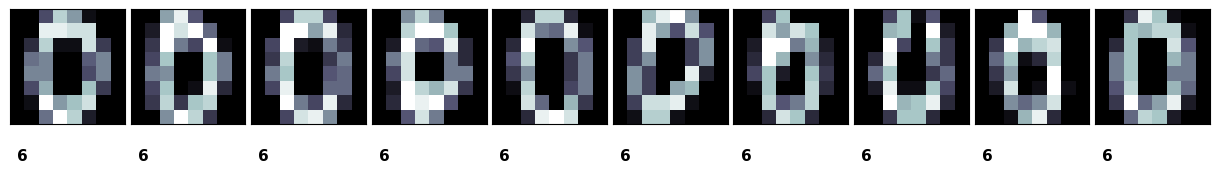

--- Amostras reunidas no Cluster de índice 7 ---


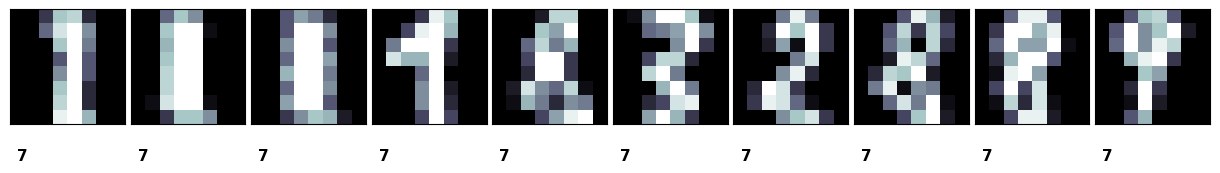

--- Amostras reunidas no Cluster de índice 8 ---


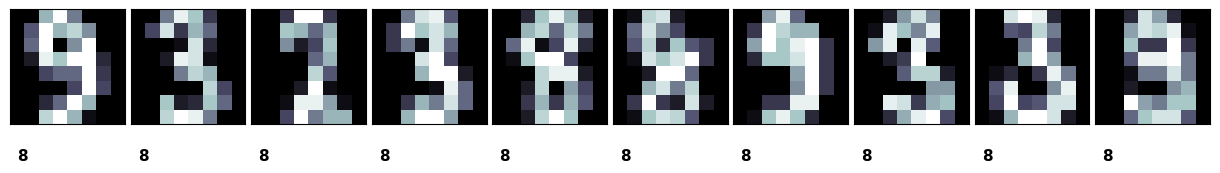

--- Amostras reunidas no Cluster de índice 9 ---


<Figure size 1200x1200 with 0 Axes>

In [65]:
# Prevendo os clusters para os dados inéditos de teste
y_pred = clf.predict(X_teste)

# Função para imprimir até 10 imagens pertencentes a um cluster específico
def print_cluster(imagens, y_pred, cluster_num):
    imagens = imagens[y_pred == cluster_num]
    y_pred = y_pred[y_pred == cluster_num]
    print_digits(imagens, y_pred, max_n=10)

# Exibindo as amostras agrupadas em cada um dos 10 clusters (de 0 a 9)
for i in range(10):
    print(f"--- Amostras reunidas no Cluster de índice {i} ---")
    print_cluster(imagens_teste, y_pred, i)

##### Avaliando um Agrupamento
Ao observar os grupos acima, vemos que alguns *clusters* ficaram extremamente nítidos (como o grupo que reuniu exclusivamente desenhos do algarismo `0` ou do algarismo `6`), enquanto outros misturaram números parecidos (como `1`, `8` e `9`).

Métricas tradicionais como **Acurácia** e **Precisão** não funcionam aqui, pois o nome do *cluster* sorteado pelo **K-Means** não coincide com o nome da classe real (se o algoritmo colocou todos os números `0` dentro do `Cluster 6`, ele fez um trabalho perfeito de agrupamento, mas a **Acurácia** seria nula por causa do rótulo trocado!).

* **Índice Aleatório Ajustado** (*Adjusted Rand Index - ARI*): Avalia o desempenho do agrupamento sabendo quais são os grupos esperados (`y_teste`).
Ele mede a similaridade entre duas partições feita pelo algoritmo (`y_pred`) e o gabarito real (`y_teste`), **ignorando permutações nos nomes dos grupos** (trocar os números dos rotulos não altera o valor desse índice). Além disso, ele corrige coincidências que ocorreriam por puro acaso.

Escala de pontuação:
  * **Valor `1.0`**: Agrupamentos idênticos (concordância perfeita, ressalvada a permutação dos rótulos). 
  * **Valor `0.0` ou próximo**: Concordância não superior à esperada por uma rotulagem aleatória, independentemente do número de *clusters* ou do tamanho da amostra. 
  * **Valores negativos (-0.5 ou menos)**: Concordância inferior à esperada ao acaso (agrupamentos discordantes). 
  * **Valores positivos (< 1.0)**: Alinhamento mais forte entre as partições à medida que a pontuação se aproxima de 1.0 (um).  

Vamos calcular o **ARI** e imprimir a **Matriz da Confusão** cruzando os dígitos reais (linhas) com os *clusters* atribuídos (colunas):

In [71]:
from sklearn import metrics

# Calculando o Índice de Rand Ajustado (atualizado para f-string do Python 3)
print(f"Índice Aleatório Ajustado (Adjusted Rand Score - ARI): {metrics.adjusted_rand_score(y_teste, y_pred):.2f}\n")
print("Matriz de Confusão - MC (linhas: dígito real de 0 a 9 | colunas: cluster atribuído de 0 a 9):")
print(metrics.confusion_matrix(y_teste, y_pred))

Índice Aleatório Ajustado (Adjusted Rand Score - ARI): 0.55

Matriz de Confusão - MC (linhas: dígito real de 0 a 9 | colunas: cluster atribuído de 0 a 9):
[[ 0  0  0  1  0  0 42  0  0  0]
 [ 0  0  0 10  7  0  0 20  0  0]
 [ 0  0  0  1 30  0  0  6  1  0]
 [ 2  1  0  0  1  0  0  3 39  0]
 [ 4  0  2 49  0  0  0  0  0  0]
 [ 0 42  0  0  0  1  0  1 15  0]
 [ 0  0  0  0  0 44  1  0  0  0]
 [35  1  5  0  0  0  0  0  0  0]
 [ 1  1  0  0  0  0  0 26 10  0]
 [ 2  2  0  3  0  0  0  1 40  0]]


Pela **Matriz de Confusão (MC)** mostrada na célula anterior, confirmamos matematicamente o que vimos nas imagens: quase todas as 43 amostras reais do **dígito `0`** (primeira linha da MC) foram colocadas juntas em um único *cluster* isolado (`42` amostras na mesma coluna)!  
Por outro lado, o **dígito `8`** (nona linha da MC) causou grande confusão ao modelo, dividindo-se entre dois *clusters* diferentes (`26` amostras em um grupo e `10` em outro).

#### 3.1.8 Limitações
O método **K-Means** é bastante susceptível a problemas quando os *clusters* são:
* De Diferentes Tamanhos
* De Diferentes Densidades
* De Diferentes Formatos (*clusters* globulares)

<img src="./img/cluster_diferentes_tamanhos.png" height="300px">

<img src="./img/cluster_diferentes_densidades.png" height="300px">

<img src="./img/cluster_diferentes_formatos.png" height="300px">

##### Diferentes Formatos

* Métricas de Distância
    - Euclidiana: $$D(\bold{X}, \bold{Y}) = \sqrt{\sum\limits_{i=1}^N (x_i-y_i)}~~~~~~~~~~ [0,\infty)$$
    - Minkowski: $$D(\bold{X}, \bold{Y}) = \left(\sqrt{\sum\limits_{i=1}^N \lvert{x_i-y_i}\rvert^p}\right)^\frac{1}{p}~~~~~~~~~~ [0,\infty)$$    
    - Cosseno: $$D(\bold{X}, \bold{Y}) = \frac{\sqrt{\sum_{i=1}^N x_i y_i}}{\sqrt{\sum_{i=1}^N {x_i}^2}\sqrt{\sum_{i=1}^N {y_i}^2}}~~~~~~~~~~ [0,1]$$     
    - Pearson: $$D(\bold{X}, \bold{Y}) = \frac{\sum_{i=1}^N (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^N {(x_i-\bar{x})}^2}{\sqrt{\sum_{i=1}^N {(y_i-\bar{y})}^2}}}~~~~~~~~~~ [-1,1]$$

#### 3.1.9 Diagrama de Voronoi - Regiões de Decisão Visuais com PCA
Não podemos desenhar na tela o formato geométrico dos 10 *clusters* do **K-Means**, pois os dados possuem 64 dimensões! 

Podemos reduzir a dimensionalidade dos dados de treinamento para **2 dimensões** (`PCA(n_components=2)`), construir uma malha fina de pontos (*meshgrid*), colorir a região de domínio de cada *cluster* e marcar a posição exata dos **10 centroides** com pontos brancos:

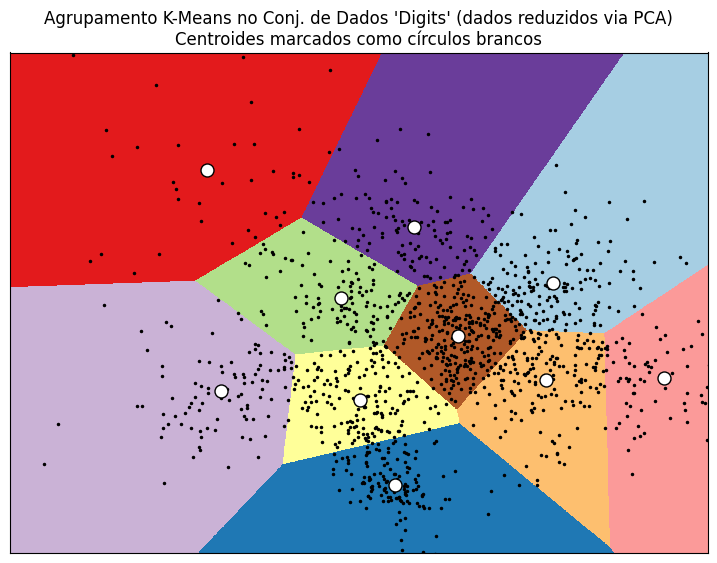

In [77]:
from sklearn import decomposition

# Reduz os dados de treinamento de 64 para 2 dimensões usando PCA
pca = decomposition.PCA(n_components=2).fit(X_treino)
X_treino_reduzido = pca.transform(X_treino)

# Definindo o passo da malha (h) e os limites do plano cartesiano 2D
h = 0.01
x_min, x_max = X_treino_reduzido[:, 0].min() + 1, X_treino_reduzido[:, 0].max() - 1
y_min, y_max = X_treino_reduzido[:, 1].min() + 1, X_treino_reduzido[:, 1].max() - 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Treina o K-Means diretamente sobre os dados reduzidos em 2D
kmeans = cluster.KMeans(init='k-means++', n_clusters=n_digitos, n_init=10, random_state=42)
kmeans.fit(X_treino_reduzido)

# Prevê o cluster de cada ponto da malha para pintar o fundo do gráfico
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Renderiza o gráfico colorido com as amostras (pontos pretos) e os centroides (bolas brancas)
plt.figure(figsize=(9, 6.5))
plt.clf()
plt.imshow(Z, interpolation='nearest', extent=(xx.min(), xx.max(), yy.min(), yy.max()), cmap=plt.cm.Paired, aspect='auto', origin='lower')
plt.plot(X_treino_reduzido[:, 0], X_treino_reduzido[:, 1], 'k.', markersize=3)

# Desenha os centroides como círculos brancos em destaque
centroides = kmeans.cluster_centers_
plt.scatter(centroides[:, 0], centroides[:, 1], marker='.', s=350, linewidths=1, color='w', edgecolors='black', zorder=10)
plt.title("Agrupamento K-Means no Conj. de Dados 'Digits' (dados reduzidos via PCA)\nCentroides marcados como círculos brancos")
plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
plt.xticks(()); plt.yticks(())
plt.show()

## 4. Métodos Alternativos de Agrupamento

Um problema típico ao utilizar o K-Means na engenharia é que, muitas vezes, **não sabemos de antemão quantos grupos ($k$) existem nos dados**. Quando não há um especialista para definir esse número, podemos recorrer a algoritmos que **calculam automaticamente a quantidade ideal de clusters**:

1. **Propagação de Afinidade (`AffinityPropagation`)**: Busca instâncias reais dentro do conjunto de dados que sejam as mais representativas das demais (chamadas de *exemplares* ou elementos canônicos) e agrupa os pontos ao redor delas. O atributo `cluster_centers_indices_` informa quais linhas da matriz foram eleitas como centro de cada grupo.

1. **Deslocamento Médio (`MeanShift`)**: Algoritmo baseado em densidade que desliza janelas em direção às regiões mais densas de pontos até convergir para os picos de concentração (centroides), disponibilizados no atributo `cluster_centers_`.

1. **Modelos de Mistura Gaussiana (`Gaussian Mixture Models - GMM`)**: Abordagem probabilística para agrupamentos, muito parecida com o algoritmo K-Means.

Vamos aplicar ambos os métodos aos nossos dados de treinamento (`X_train`) e verificar quantos grupos cada algoritmo descobre sozinho:


In [78]:
# Propagação de Afinidade (Affinity Propagation)
aff = cluster.AffinityPropagation(random_state=42)
aff.fit(X_train)
print("Quantidade de clusters descobertos pelo AffinityPropagation:", aff.cluster_centers_indices_.shape)

# Deslocamento Médio (Mean Shift)
ms = cluster.MeanShift()
ms.fit(X_treino)
print("Dimensão dos centroides descobertos pelo MeanShift (Clusters x Pixels):", ms.cluster_centers_.shape)

Quantidade de clusters descobertos pelo AffinityPropagation: (112,)
Dimensão dos centroides descobertos pelo MeanShift (Clusters x Pixels): (18, 64)


Observe como a interpretação varia conforme o critério matemático adotado: enquanto a **Propagação de Afinidade** detectou **`112` subgrupos** (tratando pequenas variações de caligrafia como grupos distintos), o **Mean Shift** agrupou os dados em **`18` clusters**!

### 4.1 Modelos de Mistura Gaussiana (*GMM*)

Exploraremos uma abordagem probabilística de agrupamento utilizando os **Modelos de Mistura Gaussiana** (*Gaussian Mixture Models* — **GMM**). Embora o procedimento de uso no `scikit-learn` seja muito semelhante ao K-Means, seu princípio teórico é bastante distinto.

O **GMM** assume que os dados foram gerados a partir de uma mistura de distribuições normais (gaussianas) finitas com parâmetros desconhecidos. Na estatística e na engenharia da qualidade, a **Distribuição Gaussiana** (curva em formato de sino) modela inúmeros fenômenos naturais — garantida pelo teorema da **Lei dos Grandes Números** (ou Teorema Central do Limite), segundo o qual a repetição de medições independentes (como medir a estatura de uma população masculina) converge para uma curva normal caracterizada por dois parâmetros:
* **Média ($\mu$)**: Indica o valor mais provável, coincidindo com o pico central do curva em formato de sino.
* **Desvio Padrão ($\sigma$) ou Variância ($\sigma^2$)**: Mede o espalhamento dos dados ao redor da média (a largura do sino). Se calcularmos a área sob a curva entre dois pontos, obtemos a probabilidade de um indivíduo apresentar estatura dentro daquele intervalo.

<div style="text-align: center; margin: 20px 0;">
    <!-- Reprodução/Ilustração do Histograma com Curva Normal do Livro -->
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/7/74/Normal_Distribution_PDF.svg/500px-Normal_Distribution_PDF.svg.png" alt="Curva de Distribuição Normal Gaussiana" style="width: 45%; max-width: 480px; height: auto; border-radius: 6px; box-shadow: 0 4px 8px rgba(0,0,0,0.15);">
    <p style="font-size: 0.9em; color: #555; margin-top: 8px;">
        Funções de Densidade de Probabilidade <b>Gaussiana</b>: o centro do sino define a média ($\mu$) do grupo, enquanto a variância ($\sigma^2$) controla a abertura da curva.
    </p>
</div>

### 4.2 O Algoritmo Maximização da Esperança (*Expectation-Maximization* - EM)
Em problemas com múltiplos atributos (distribuição multivariada, como os nossos 64 pixels), o GMM assume que cada cluster possui sua própria distribuição normal multivariada. O objetivo do método é estimar a média (centroide) e a variância de cada um dos $k$ grupos utilizando um algoritmo iterativo chamado **Expectation-Maximization (EM)**, atribuindo cada ponto à distribuição mais provável.

No `scikit-learn` moderno, essa técnica é implementada pela classe **`GaussianMixture`** (do módulo `sklearn.mixture`), onde configuramos o parâmetro `covariance_type` para indicar como esperamos que as variáveis (pixels) se relacionem espacialmente (usaremos `covariance_type='tied'`, onde os grupos compartilham a mesma matriz de covariância geral).

Além do **Índice de Rand Ajustado**, avaliaremos o resultado com mais duas métricas complementares do `scikit-learn`:
* **Homogeneidade (`homogeneity_score`):** Mede se cada cluster contém apenas amostras de uma única classe real (varia de `0.0` a `1.0`).
* **Completude (`completeness_score`):** Mede se todas as amostras de uma determinada classe real foram colocadas juntas no mesmo cluster (varia de `0.0` a `1.0`).


In [80]:
from sklearn import mixture

# Nota de Atualização (Python 3 / scikit-learn atual):
# A classe antiga mixture.GMM foi substituída por mixture.GaussianMixture
gm = mixture.GaussianMixture(n_components=n_digitos, covariance_type='tied', random_state=42)
gm.fit(X_treino)

# Prevendo os clusters no conjunto de teste e avaliando as 3 métricas científicas
y_pred = gm.predict(X_teste)

print(f"Índice Aleatório Ajustado (Adjusted Rand Score): {metrics.adjusted_rand_score(y_teste, y_pred):.2f}")
print(f"Pontuação de Homogeneidade (Homogeneity Score) : {metrics.homogeneity_score(y_teste, y_pred):.2f}")
print(f"Pontuação de Completude (Completeness Score)   : {metrics.completeness_score(y_teste, y_pred):.2f}")

Índice Aleatório Ajustado (Adjusted Rand Score): 0.49
Pontuação de Homogeneidade (Homogeneity Score) : 0.65
Pontuação de Completude (Completeness Score)   : 0.71


##### Interpretação Comparativa das Métricas: Homogeneidade e Completude

Na execução original da bibliografia de referência, o Modelo de Mistura Gaussiana (GMM) superou o K-Means no Índice de Rand Ajustado ($0.65$ contra $0.59$), indicando um melhor alinhamento estatístico dos clusters gerados com os dígitos originais. *(Nota técnica: nas versões atuais do `scikit-learn`, devido a mudanças internas na inicialização numérica da classe `GaussianMixture`, o K-Means pode apresentar pontuação ligeiramente superior dependendo da semente aleatória, mas o princípio de avaliação permanece idêntico).*

Para aprofundar o diagnóstico, incluímos duas métricas fundamentais do módulo `sklearn.metrics`, que variam no intervalo de `0.0` a `1.0` (quanto maior o valor, melhor o agrupamento):

* **Homogeneidade (*Homogeneity*):** Avalia a pureza interna de cada grupo. O valor máximo (`1.0`) indica que cada cluster contém exclusivamente amostras pertencentes a uma única classe real — ou seja, o algoritmo conseguiu agrupar apenas elementos verdadeiramente similares sem misturar classes diferentes.
* **Completude (*Completeness*):** Avalia a concentração das classes. É satisfeita (`1.0`) quando todas as amostras existentes de uma determinada classe real são colocadas juntas dentro do mesmo cluster (significando que o modelo reuniu todas as instâncias daquele dígito em um único grupo, em vez de fragmentá-las em vários clusters menores).

<div style="background-color: #cfcff8; border-left: 5px solid; border-right: 5px solid #773014; padding: 15px; margin: 15px -25px; border-radius: 4px; color: #5b0137;">
    <p style="color: #6d3651;">💡 <b>Analogia Científica (Supervisionado vs. Não Supervisionado):</b></p>
    Podemos compreender a <b>Homogeneidade</b> e a <b>Completude</b> como as versões não supervisionadas da <b>Precisão (<i>Precision</i>)</b> e da <b>Sensibilidade/Revocação (<i>Recall</i>)</b> que utilizamos na classificação supervisionada!
</div>

## Resumo - Aprendizado Não Supervisionado

Vimos os principais métodos de **Aprendizado Não Supervisionado** e o seu papel prático na ciência de dados e na engenharia:

1. **Análise Exploratória e Redução de Dimensionalidade (`PCA`)**: Vimos como algoritmos não supervisionados permitem inspecionar rapidamente a estrutura interna de bases de dados complexas e comprimir dezenas de variáveis em poucos eixos ortogonais. Essa etapa é extremamente útil como preparação antes de treinarmos um modelo supervisionado.

1. **Agrupamento de Dados Não Rotulados (`K-Means`, `Affinity Propagation`, `Mean Shift` e `GMM`)**: Aplicamos técnicas de *clustering* para descobrir padrões e organizar amostras por similaridade geométrica ou probabilística sem utilizar uma classe alvo (`y`), viabilizando a criação de sistemas inteligentes sobre dados brutos não rotulados.

#### Implementação em Python - K-Means

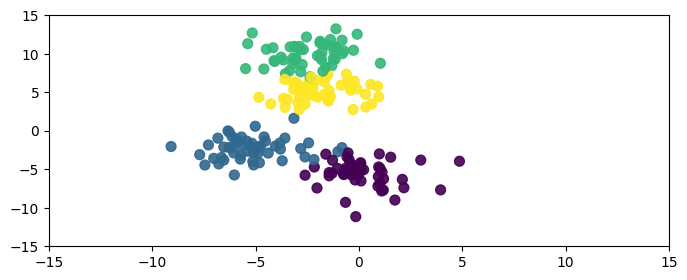

In [85]:
## GERAÇÃO DE DADOS FICTÍCIOS
# 'make_blobs()' é uma função do módulo sklearn.datasets (do scikit-learn) usada para gerar conjuntos de dados sintéticos com 
#   agrupamentos (clusters) gaussianos isotrópicos, ideal para testar e visualizar algoritmos de agrupamento e classificação
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

k = 4               # quantidade de clusters
n = 200             # quantidade de pontos
dados = make_blobs(n_samples=n, n_features=2, centers=k, cluster_std=1.5, random_state=50)
X = dados[0]        # atributos das observações
rotulos = dados[1]  # classe alvo (conhecida a priori)

plt.figure(figsize=(8,3))
plt.scatter(X[:,0], X[:,1], c=rotulos, cmap='viridis', s=50, alpha=0.9)
plt.xlim(-15, 15); plt.ylim(-15, 15)
plt.show()

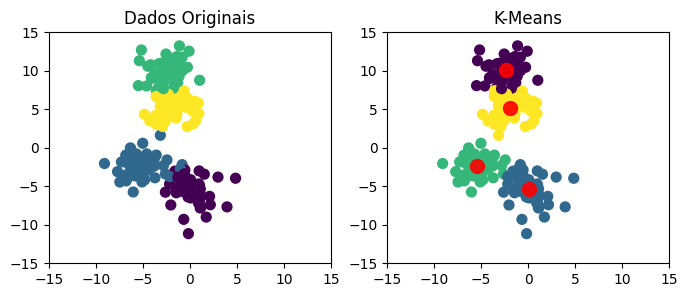

In [84]:
## AGRUPAMENTO COM K-MEANS
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=k)    # cria modelo com 'k' grupos
kmeans.fit(X)                    # ajusta o modelo para o conj. de dados X (criado ficticiamente)
y_pred = kmeans.fit_predict(X)   # faz a predição, identificando os clusters

plt.figure(figsize=(8,3)); plt.subplot(1,2,2)
plt.scatter(X[:,0], X[:,1], c=y_pred, cmap='viridis', s=50)
plt.xlim(-15, 15); plt.ylim(-15, 15); plt.title("K-Means")
centroides = kmeans.cluster_centers_
plt.scatter(centroides[:,0], centroides[:,1], c='red', s=100, alpha=0.9)
plt.subplot(1,2,1)
plt.scatter(X[:,0], X[:,1], c=rotulos, cmap='viridis', s=50)
plt.xlim(-15, 15); plt.ylim(-15, 15); plt.title("Dados Originais")
plt.show()

A quantidade de *clusters* ideal pode ser estimado com o **método do cotovelo**. Esse método mede a distância média dos pontos de um *cluster* até o seu centroide (*Within-Cluster Sum of Squares*) para diferentes valores de `k`:
$$WCSS = \sum_{i=1}^{N_c} \sum_{\bold{x} \in C_i}^{N} d(\bold{x},\bar{x}_{C_i})$$
onde:  
$N_c$ é a quantidade de centroides (agrupamentos)  
$N$ é a quantidade de pontos em cada agrupamento

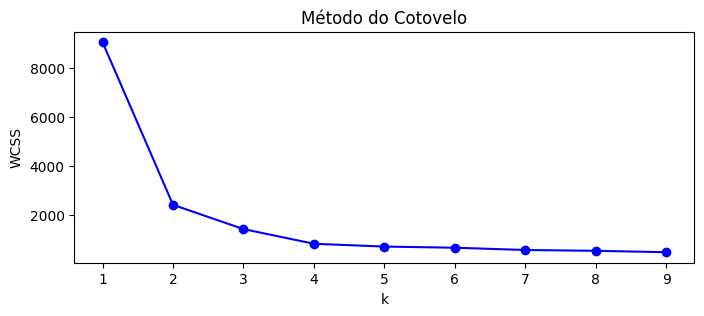

In [86]:
WCSS = []
K = range(1,10)
for k in K:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)

plt.figure(figsize=(8,3))
plt.plot(K, WCSS, '-bo'); plt.xlabel('k'); plt.ylabel('WCSS'); plt.title('Método do Cotovelo')
plt.show()

# Exercício: Monitoramento Industrial Não Supervisionado com PCA e K-Means
## Contextualização do Problema
Em uma planta industrial automatizada, **300 motores de indução trifásicos** são monitorados continuamente por **6 sensores simultâneos**. No entanto, a equipe de engenharia não catalogou previamente o estado de operação de cada leitura (temos apenas os dados brutos na matriz `X_sensores`, sem rótulos).

Suspeita-se que as máquinas operem em **3 regimes distintos ($k = 3$)**:
* **Regime Normal:** Temperaturas, vibrações e correntes estabilizadas.
* **Anomalia Mecânica (Desalinhamento/Rolamento):** Elevação acentuada nas vibrações axial/radial e no ruído acústico.
* **Anomalia Elétrica (Sobrecarga):** Elevação severa na corrente elétrica de fase e na temperatura do estator.

Confira os **6 atributos medidos ($X$)** gerados na célula de código a seguir:

<center>

| Sensor (Atributo) | Índice | Grandeza Física e Unidade |
|:---:|:---:|:---|
| `Temp_Estator_C` | 0 | Temperatura do enrolamento do estator (°C) |
| `Temp_Mancal_C` | 1 | Temperatura do mancal de rolamento (°C) |
| `Vibracao_Axial_mms` | 2 | Velocidade de vibração no eixo axial ($\text{mm/s}$) |
| `Vibracao_Radial_mms` | 3 | Velocidade de vibração no eixo radial ($\text{mm/s}$) |
| `Corrente_Fase_A` | 4 | Corrente elétrica de alimentação em Ampères ($\text{A}$) |
| `Ruido_Acustico_dB` | 5 | Nível de pressão sonora emitido pelo equipamento ($\text{dB}$) |

</center>

## Roteiro
Execute a célula geradora de dados abaixo e escreva o código para realizar as **4 etapas**:

1. **Padronização de Escala (`scale`):** Utilize a função `scale(X_sensores)` do módulo `sklearn.preprocessing` para deixar todas as 6 grandezas físicas com média zero e variância unitária.
2. **Redução de Dimensionalidade (`PCA`):** Instancie o objeto `PCA(n_components=2, random_state=42)` e aplique o método `.fit_transform()` nos dados padronizados, comprimindo as 6 dimensões para apenas 2 Componentes Principais (`X_pca`).
3. **Agrupamento com `KMeans` e Visualização 2D:** 
   * Instancie e treine o algoritmo `KMeans(init='k-means++', n_clusters=3, n_init=10, random_state=42)` sobre os dados reduzidos `X_pca`.
   * Gere um gráfico de dispersão (`plt.scatter`) exibindo os 3 clusters coloridos e marque os 3 centroides (`kmeans.cluster_centers_`) com círculos ou estrelas em destaque.
4. **Avaliação Científica Não Supervisionada:** Utilizando o vetor `y_real_oculto` (apenas para conferência final!), calcule e imprima o **Índice de Rand Ajustado** (`adjusted_rand_score`), a **Homogeneidade** (`homogeneity_score`), a **Completude** (`completeness_score`) e a **Matriz de Confusão** (`confusion_matrix`).

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import scale
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn import metrics

# Geração reprodutível das leituras de 300 motores industriais (6 sensores por motor)
np.random.seed(42)
n_por_regime = 100

# Grupo 0: Operação Normal
g0 = np.column_stack([
    np.random.normal(65, 8, n_por_regime),    # Temp_Estator_C
    np.random.normal(60, 7, n_por_regime),    # Temp_Mancal_C
    np.random.normal(3.0, 1.2, n_por_regime), # Vibracao_Axial_mms
    np.random.normal(3.2, 1.2, n_por_regime), # Vibracao_Radial_mms
    np.random.normal(17, 3.0, n_por_regime),  # Corrente_Fase_A
    np.random.normal(70, 6, n_por_regime)     # Ruido_Acustico_dB
])

# Grupo 1: Anomalia Mecânica (Alta vibração e ruído)
g1 = np.column_stack([
    np.random.normal(70, 8, n_por_regime),
    np.random.normal(72, 7, n_por_regime),
    np.random.normal(5.2, 1.3, n_por_regime),
    np.random.normal(5.6, 1.3, n_por_regime),
    np.random.normal(19, 3.0, n_por_regime),
    np.random.normal(80, 7, n_por_regime)
])

# Grupo 2: Anomalia Elétrica (Alta corrente e aquecimento no estator)
g2 = np.column_stack([
    np.random.normal(82, 8, n_por_regime),
    np.random.normal(70, 7, n_por_regime),
    np.random.normal(3.6, 1.2, n_por_regime),
    np.random.normal(3.8, 1.2, n_por_regime),
    np.random.normal(24, 3.2, n_por_regime),
    np.random.normal(75, 6, n_por_regime)
])

# Empilhando e embaralhando as 300 amostras
X_bruto = np.vstack([g0, g1, g2]).round(2)
y_gabarito = np.array([0]*n_por_regime + [1]*n_por_regime + [2]*n_por_regime)

indices = np.random.permutation(len(y_gabarito))
X_sensores = X_bruto[indices]
y_real_oculto = y_gabarito[indices] # Guardado apenas para avaliação no Passo 4!

nomes_sensores = ['Temp_Estator_C', 'Temp_Mancal_C', 'Vibracao_Axial_mms', 
                  'Vibracao_Radial_mms', 'Corrente_Fase_A', 'Ruido_Acustico_dB']

print("Dimensão da Matriz X_sensores (Motores x Sensores):", X_sensores.shape)
print("Sensores monitorados:", nomes_sensores)
print("Leitura do Motor [0]:", X_sensores[0])

Dimensão da Matriz X_sensores (Motores x Sensores): (300, 6)
Sensores monitorados: ['Temp_Estator_C', 'Temp_Mancal_C', 'Vibracao_Axial_mms', 'Vibracao_Radial_mms', 'Corrente_Fase_A', 'Ruido_Acustico_dB']
Leitura do Motor [0]: [89.16 73.9   6.2   1.56 23.75 80.08]


# Fontes
* "Elbow Method for optimal value of k in K-Means"; 02/05/26; disponível em https://www.geeksforgeeks.org/machine-learning/elbow-method-for-optimal-value-of-k-in-kmeans/; acessado em 21/11/26.
* Chris Piech; "K Means"; 2013; disponível em https://stanford.edu/~cpiech/cs221/handouts/kmeans.html; acessado em 21/11/26.
* "Scikit-learn Tutorial"; disponível em http://scikit-learn.org/.
* "Scikit-learn Getting Started"; disponível em https://scikit-learn.org/stable/.
* Prof. Francisco Rodrigues; "Algoritmo k-means (k-médias)"; vídeo Youtube 10'18"; 18/11/21; disponível em https://www.youtube.com/watch?v=njRYKzRKBPY; acessado em 21/11/26.